In [27]:
!pip -q install scikit-learn pandas numpy matplotlib torch

In [28]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cpu
PyTorch version: 2.11.0+cpu


In [29]:
from google.colab import files
from io import BytesIO

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a CSV file.")

file_name = next(iter(uploaded))

df = pd.read_csv(BytesIO(uploaded[file_name]))

print("Uploaded:", file_name)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Saving GSPC.csv to GSPC (2).csv
Uploaded: GSPC (2).csv
Shape: (24801, 7)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1927-12-30,17.660000,17.660000,17.660000,17.660000,17.660000,0
1,1928-01-03,17.760000,17.760000,17.760000,17.760000,17.760000,0
2,1928-01-04,17.719999,17.719999,17.719999,17.719999,17.719999,0
3,1928-01-05,17.549999,17.549999,17.549999,17.549999,17.549999,0
4,1928-01-06,17.660000,17.660000,17.660000,17.660000,17.660000,0


In [30]:
df.columns = [str(c).strip() for c in df.columns]

date_col = next(
    (c for c in df.columns if c.lower() == "date"),
    None
)

close_col = next(
    (c for c in df.columns if c.lower() == "close"),
    None
)

if close_col is None:
    close_col = next(
        (c for c in df.columns if c.lower() == "adj close"),
        None
    )

if date_col is None or close_col is None:
    raise ValueError(
        "Date and Close/Adj Close columns are required. "
        f"Found columns: {df.columns.tolist()}"
    )

df = df[[date_col, close_col]].copy()
df.columns = ["Date", "Close"]

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

df = (
    df.dropna(subset=["Date", "Close"])
      .sort_values("Date")
      .drop_duplicates(subset=["Date"], keep="last")
      .reset_index(drop=True)
)

if (df["Close"] <= 0).any():
    raise ValueError("Closing prices must be positive.")

if len(df) < 100:
    raise ValueError("Dataset is too small for this experiment.")

print("Cleaned dataset:", df.shape)
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

display(df.head())
display(df.tail())

Cleaned dataset: (24801, 2)
Start: 1927-12-30 00:00:00
End: 2026-09-25 00:00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Date,Close
0,1927-12-30,17.660000
1,1928-01-03,17.760000
2,1928-01-04,17.719999
3,1928-01-05,17.549999
4,1928-01-06,17.660000


,Date,Close
24796,2026-09-21,7764.700195
24797,2026-09-22,7764.640137
24798,2026-09-23,7706.029785
24799,2026-09-24,7704.129883
24800,2026-09-25,7743.410156


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


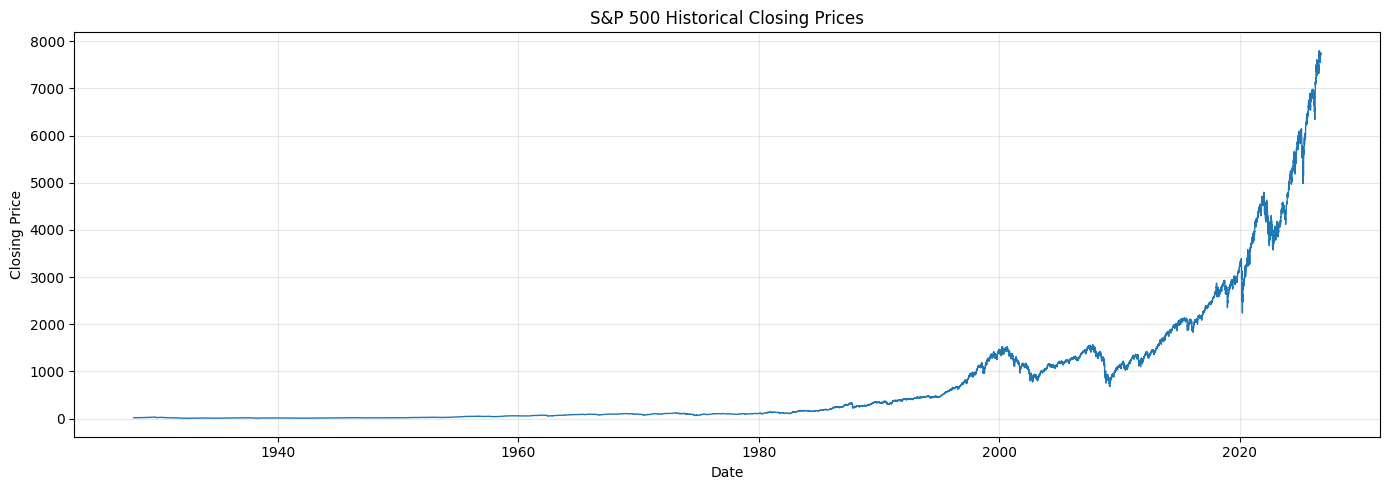

In [31]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["Close"], linewidth=1)

plt.title("S&P 500 Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
TRAIN_END = pd.Timestamp("2022-12-31")
VAL_START = pd.Timestamp("2023-01-01")
VAL_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")
TEST_END = pd.Timestamp("2026-12-31")

LOOKBACK = 60

train_rows = df[df["Date"] <= TRAIN_END]
val_rows = df[
    (df["Date"] >= VAL_START) &
    (df["Date"] <= VAL_END)
]
test_rows = df[
    (df["Date"] >= TEST_START) &
    (df["Date"] <= TEST_END)
]

print("Training rows:", len(train_rows))
print("Validation rows:", len(val_rows))
print("Testing rows:", len(test_rows))

if train_rows.empty or val_rows.empty or test_rows.empty:
    raise ValueError(
        "One or more date ranges contain no observations. "
        "Check the dataset dates or adjust the split dates."
    )

Training rows: 23865
Validation rows: 502
Testing rows: 434


In [33]:
df["Log_Return"] = np.log(
    df["Close"] / df["Close"].shift(1)
)

df = df.dropna(subset=["Log_Return"]).reset_index(drop=True)

# Fit only on training-period returns
train_return_mask = df["Date"] <= TRAIN_END

return_scaler = StandardScaler()

return_scaler.fit(
    df.loc[train_return_mask, ["Log_Return"]]
)

df["Scaled_Return"] = return_scaler.transform(
    df[["Log_Return"]]
).ravel()

print("Scaler fitted on training data only.")
display(df[["Date", "Close", "Log_Return", "Scaled_Return"]].head())

Scaler fitted on training data only.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Date,Close,Log_Return,Scaled_Return
0,1928-01-03,17.760000,0.005647,0.450980
1,1928-01-04,17.719999,-0.002255,-0.206344
2,1928-01-05,17.549999,-0.009640,-0.820722
3,1928-01-06,17.660000,0.006248,0.501041
4,1928-01-09,17.500000,-0.009101,-0.775909


In [34]:
X_all = []
y_all = []
target_dates = []
target_prices = []
previous_prices = []

scaled_returns = df["Scaled_Return"].to_numpy()
actual_prices = df["Close"].to_numpy()
dates = df["Date"].to_numpy()

for i in range(LOOKBACK, len(df)):

    X_all.append(
        scaled_returns[i - LOOKBACK:i]
    )

    y_all.append(
        scaled_returns[i]
    )

    target_dates.append(dates[i])
    target_prices.append(actual_prices[i])
    previous_prices.append(actual_prices[i - 1])

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.float32)

target_dates = pd.to_datetime(target_dates)
target_prices = np.asarray(target_prices)
previous_prices = np.asarray(previous_prices)

train_mask = target_dates <= TRAIN_END

val_mask = (
    (target_dates >= VAL_START) &
    (target_dates <= VAL_END)
)

test_mask = (
    (target_dates >= TEST_START) &
    (target_dates <= TEST_END)
)

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_val = X_all[val_mask]
y_val = y_all[val_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_dates = target_dates[test_mask]
test_actual = target_prices[test_mask]
test_previous = previous_prices[test_mask]

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("A sequence split is empty. Check your date ranges.")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (23804, 60)
X_val: (502, 60)
X_test: (434, 60)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [35]:
naive_predictions = test_previous.copy()

print("Naive baseline ready.")
print("First five predictions:", naive_predictions[:5])
print("First five actual prices:", test_actual[:5])

Naive baseline ready.
First five predictions: [5881.629883 5868.549805 5942.470215 5975.379883 5909.029785]
First five actual prices: [5868.549805 5942.470215 5975.379883 5909.029785 5918.25    ]


In [36]:
linear_model = LinearRegression()

X_train_linear = X_train.reshape(len(X_train), LOOKBACK)
X_val_linear = X_val.reshape(len(X_val), LOOKBACK)
X_test_linear = X_test.reshape(len(X_test), LOOKBACK)

linear_model.fit(X_train_linear, y_train)

linear_val_scaled = linear_model.predict(X_val_linear)
linear_test_scaled = linear_model.predict(X_test_linear)

# Return predictions to the original log-return scale
linear_val_returns = return_scaler.inverse_transform(
    linear_val_scaled.reshape(-1, 1)
).ravel()

linear_test_returns = return_scaler.inverse_transform(
    linear_test_scaled.reshape(-1, 1)
).ravel()

# Reconstruct next-day closing prices
linear_val_previous = df.loc[
    (df["Date"] >= VAL_START) &
    (df["Date"] <= VAL_END),
    "Close"
].to_numpy()

# Use the previous available price for each validation target
val_indices = np.flatnonzero(val_mask)
val_previous = previous_prices[val_indices]

linear_val_prices = val_previous * np.exp(linear_val_returns)

linear_predictions = (
    test_previous * np.exp(linear_test_returns)
)

print("Linear Regression trained.")
print("First five predictions:", linear_predictions[:5])

Linear Regression trained.
First five predictions: [5880.97781822 5869.99235062 5942.23077659 5975.11774895 5914.7813028 ]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
X_train_t = torch.tensor(
    X_train.reshape(-1, LOOKBACK, 1),
    dtype=torch.float32
)

y_train_t = torch.tensor(
    y_train.reshape(-1, 1),
    dtype=torch.float32
)

X_val_t = torch.tensor(
    X_val.reshape(-1, LOOKBACK, 1),
    dtype=torch.float32,
    device=device
)

y_val_t = torch.tensor(
    y_val.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)

X_test_t = torch.tensor(
    X_test.reshape(-1, LOOKBACK, 1),
    dtype=torch.float32,
    device=device
)

train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

print("Training tensor:", X_train_t.shape)
print("Validation tensor:", X_val_t.shape)
print("Testing tensor:", X_test_t.shape)

Training tensor: torch.Size([23804, 60, 1])
Validation tensor: torch.Size([502, 60, 1])
Testing tensor: torch.Size([434, 60, 1])


In [38]:
class StockLSTM(nn.Module):

    def __init__(self, input_size=1, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        return self.fc(last_output)


model = StockLSTM().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print(model)

StockLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [39]:
EPOCHS = 50
PATIENCE = 7

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    model.train()
    train_losses = []

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = model(xb)
        loss = criterion(predictions, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_losses.append(loss.item())

    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val_t)
        val_loss = criterion(val_predictions, y_val_t).item()

    train_loss = float(np.mean(train_losses))

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model.")

model.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Epoch 01/50 | Train Loss: 1.002690 | Validation Loss: 0.457181
Epoch 02/50 | Train Loss: 1.002174 | Validation Loss: 0.455912
Epoch 03/50 | Train Loss: 1.001612 | Validation Loss: 0.457156
Epoch 04/50 | Train Loss: 1.001013 | Validation Loss: 0.458913
Epoch 05/50 | Train Loss: 0.998444 | Validation Loss: 0.454588
Epoch 06/50 | Train Loss: 0.996290 | Validation Loss: 0.458384
Epoch 07/50 | Train Loss: 0.994335 | Validation Loss: 0.454877
Epoch 08/50 | Train Loss: 0.987775 | Validation Loss: 0.456137
Epoch 09/50 | Train Loss: 0.987799 | Validation Loss: 0.456118
Epoch 10/50 | Train Loss: 0.980705 | Validation Loss: 0.458029
Epoch 11/50 | Train Loss: 0.979677 | Validation Loss: 0.455772
Epoch 12/50 | Train Loss: 0.973913 | Validation Loss: 0.456625
Early stopping triggered.
Best validation loss: 0.45458778738975525


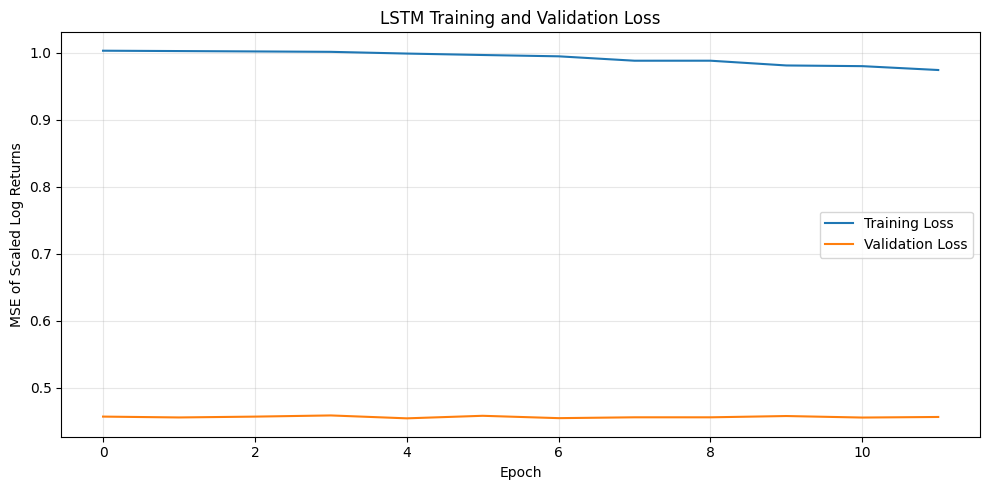

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE of Scaled Log Returns")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
model.eval()

with torch.no_grad():
    lstm_test_scaled = model(X_test_t).cpu().numpy().ravel()

# Convert scaled returns to original log-return units
lstm_test_returns = return_scaler.inverse_transform(
    lstm_test_scaled.reshape(-1, 1)
).ravel()

# Convert log-return forecasts into prices
lstm_predictions = (
    test_previous * np.exp(lstm_test_returns)
)

print("First five LSTM predictions:", lstm_predictions[:5])
print("First five actual prices:", test_actual[:5])

First five LSTM predictions: [5882.1964081  5870.20992175 5948.22311234 5981.89476895 5911.86433584]
First five actual prices: [5868.549805 5942.470215 5975.379883 5909.029785 5918.25    ]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
def evaluate_model(name, actual, predicted, previous_close):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    actual_direction = actual > previous_close
    predicted_direction = predicted > previous_close

    directional_accuracy = np.mean(
        actual_direction == predicted_direction
    ) * 100

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Directional Accuracy (%)": directional_accuracy
    }


results = [
    evaluate_model(
        "Naive Previous Close",
        test_actual,
        naive_predictions,
        test_previous
    ),
    evaluate_model(
        "Linear Regression",
        test_actual,
        linear_predictions,
        test_previous
    ),
    evaluate_model(
        "LSTM",
        test_actual,
        lstm_predictions,
        test_previous
    )
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

best_price_model = results_df.loc[
    results_df["MAE"].idxmin(),
    "Model"
]

print("Lowest test MAE:", best_price_model)

,Model,MAE,RMSE,Directional Accuracy (%)
0,Naive Previous Close,44.7431,63.7133,44.7005
1,Linear Regression,45.1331,63.8595,52.7650
2,LSTM,44.7377,63.7755,54.1475


Lowest test MAE: LSTM


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


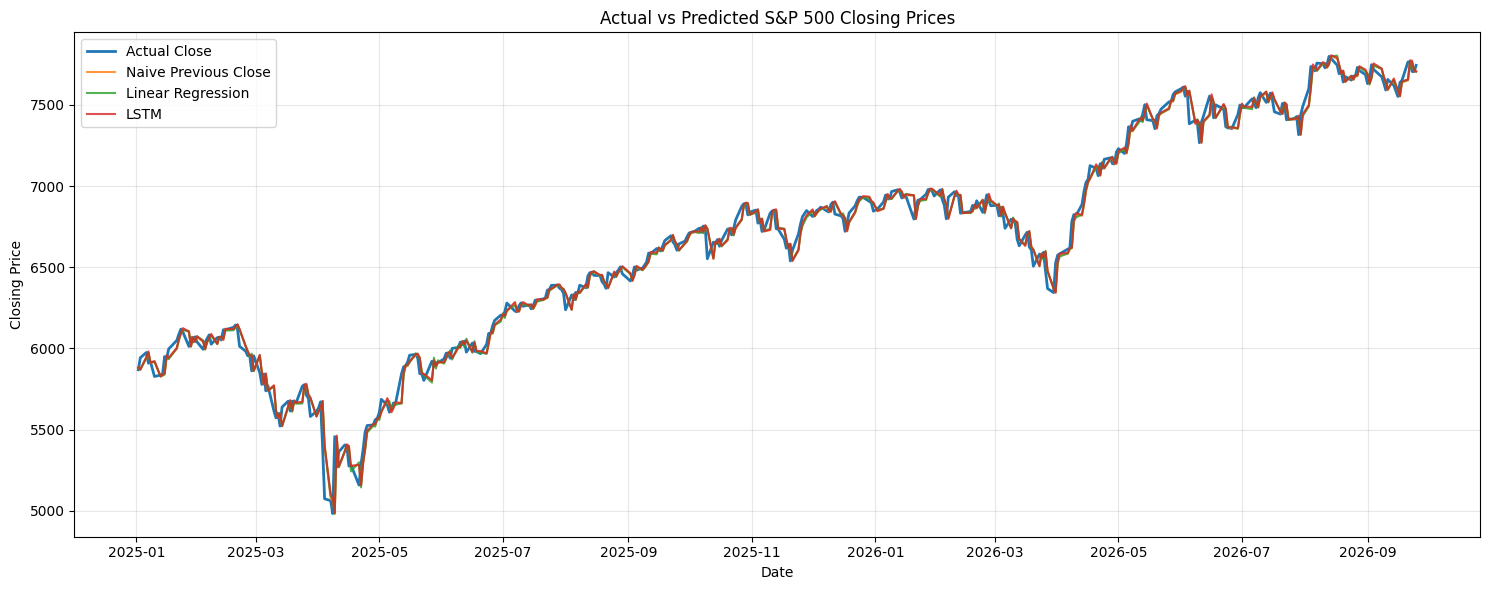

In [43]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    test_actual,
    label="Actual Close",
    linewidth=2
)

plt.plot(
    test_dates,
    naive_predictions,
    label="Naive Previous Close",
    alpha=0.8
)

plt.plot(
    test_dates,
    linear_predictions,
    label="Linear Regression",
    alpha=0.8
)

plt.plot(
    test_dates,
    lstm_predictions,
    label="LSTM",
    alpha=0.8
)

plt.title("Actual vs Predicted S&P 500 Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

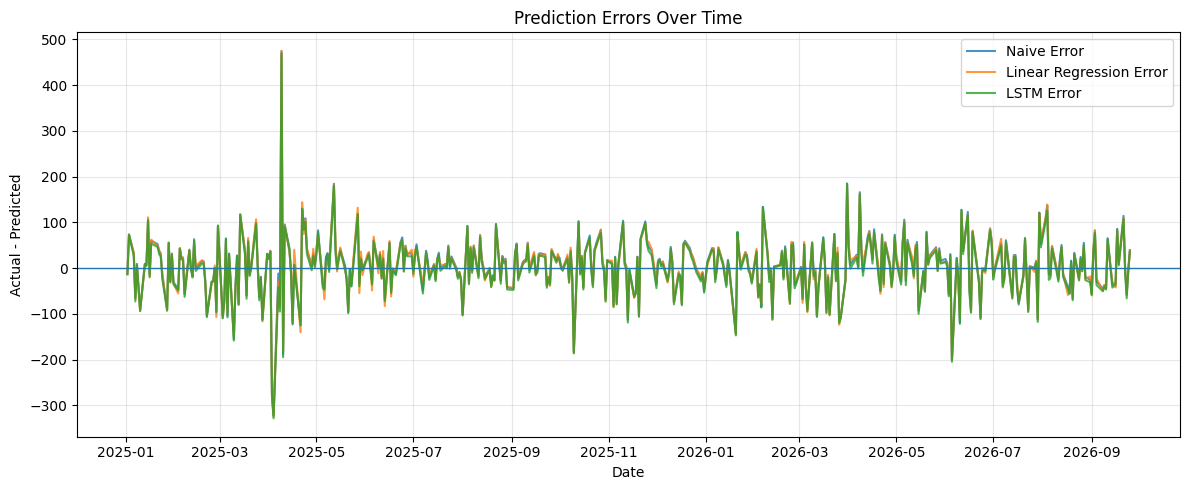

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    test_actual - naive_predictions,
    label="Naive Error",
    alpha=0.8
)

plt.plot(
    test_dates,
    test_actual - linear_predictions,
    label="Linear Regression Error",
    alpha=0.8
)

plt.plot(
    test_dates,
    test_actual - lstm_predictions,
    label="LSTM Error",
    alpha=0.8
)

plt.axhline(0, linewidth=1)

plt.title("Prediction Errors Over Time")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()